#### Tarea 5
## Resde neuronales convucionales (CNN)

### Introducción
Las redes neuronales convolucionales son un tipo de red neuronal diseñada especialmente para analizar imágenes y otros datos con estructura espacial, como videos o mapas. Utilizan datos tridimensionales para tareas de clasificación de imágenes y reconocimiento de objetos. (¿Qué Son las Redes Neuronales Convolucionales? | IBM, 2026) 

El objectivo de esta tarea es diseñar y evaluar una red neuronal convolucional (CNN) que utilice Global Average Pooling (GAP) para clasificar imágenes del conjunto de datos MNIST, buscando superar el 95% de exactitud en validación con menos de 54 330 parámetros entrenables.

Para ello, se explorarán diferentes arquitecturas, modificando características como el número de filtros, la profundidad y las operaciones de pooling. Se seleccionará el modelo con menor cantidad de parámetros entre aquellos que cumplan los requisitos establecidos.

Finalmente, se comparará su desempeño con las arquitecturas de referencia CNN + Flatten y CNN + GAP, evaluando su capacidad para reconocer dígitos desplazados 0, 2 y 4 píxeles.

In [4]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from IPython.display import display
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from tensorflow import keras

### 1. Preparación de los datos

Se utilizará el conjunto de datos MNIST, compuesto por imágenes de dígitos manuscritos del 0 al 9.

Para mantener las condiciones de los experimentos originales, se utilizarán 8 000 imágenes de entrenamiento, 1 500 de validación y 2 000 de prueba, con una semilla de 42.

Las imágenes originales de 28 × 28 píxeles se normalizarán al intervalo [0, 1] y se les agregará un margen negro de cuatro píxeles en cada lado, obteniendo imágenes de 36 × 36 píxeles. Este margen permitirá evaluar posteriormente el efecto de desplazar los dígitos.

In [5]:
# Configuración de los experimentos
SEMILLA = 42
N_ENT = 8000
N_VAL = 1500
N_PRUEBA = 2000
MARGEN = 4

keras.utils.set_random_seed(SEMILLA)

plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False
})


In [6]:
# Cargar MNIST
(x_des, y_des), (x_test, y_test) = keras.datasets.mnist.load_data()

# Partición estratificada de entrenamiento y validación
i_ent, i_val = train_test_split(
    np.arange(len(y_des)),
    train_size=N_ENT,
    test_size=N_VAL,
    stratify=y_des,
    random_state=SEMILLA
)

# Selección estratificada del conjunto de prueba
i_prueba, _ = train_test_split(
    np.arange(len(y_test)),
    train_size=N_PRUEBA,
    stratify=y_test,
    random_state=SEMILLA
)

# Agregar margen negro y normalizar
def preparar_imagenes(imagenes):
    imagenes = np.pad(
        imagenes,
        ((0, 0), (MARGEN, MARGEN), (MARGEN, MARGEN))
    )
    return imagenes[..., None].astype(np.float32) / 255.0

# Preparar los conjuntos
X_ent = preparar_imagenes(x_des[i_ent])
y_ent = y_des[i_ent]

X_val = preparar_imagenes(x_des[i_val])
y_val = y_des[i_val]

X_prueba = preparar_imagenes(x_test[i_prueba])
y_prueba = y_test[i_prueba]

FORMA = X_ent.shape[1:]

# Verificar dimensiones
for nombre, X in [
    ("Entrenamiento", X_ent),
    ("Validación", X_val),
    ("Prueba", X_prueba)
]:
    print(f"{nombre}: {X.shape}")


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Entrenamiento: (8000, 36, 36, 1)
Validación: (1500, 36, 36, 1)
Prueba: (2000, 36, 36, 1)


### 2. Modelos de referencia

Se utilizarán dos arquitecturas CNN como punto de comparación:

- **CNN + Flatten:** conserva la información espacial de los mapas de características al convertirlos en un vector antes de la clasificación.
- **CNN + GAP:** utiliza Global Average Pooling para promediar espacialmente cada mapa de características, reduciendo considerablemente el número de parámetros.

In [7]:
referencias = pd.DataFrame({
    "Modelo": ["CNN + Flatten", "CNN + GAP"],
    "Parámetros": [54330, 2650],
    "Validación (%)": [96.87, 44.07],
    "Prueba 0 px (%)": [97.15, 46.35],
    "Prueba 4 px (%)": [37.21, 46.38]
})

display(referencias)

,Modelo,Parámetros,Validación (%),Prueba 0 px (%),Prueba 4 px (%)
0,CNN + Flatten,54330,96.87,97.15,37.21
1,CNN + GAP,2650,44.07,46.35,46.38


#### 2.1. Arquitecturas base

Ambos modelos utilizan dos capas convolucionales de 16 filtros con kernels de 3×3, activación ReLU y una capa MaxPooling de 2×2. La única diferencia entre las arquitecturas es la operación utilizada antes de la clasificación:

- **Flatten:** transforma los mapas de características en un vector que conserva su información espacial.
- **Global Average Pooling (GAP):** calcula el promedio de cada mapa de características, reduciendo la cantidad de parámetros entrenables.

Finalmente, ambos modelos utilizan una capa Dense de 10 neuronas con activación Softmax para clasificar los dígitos.

In [8]:
# Configuración del entrenamiento
CAPAS = (16, 16)
LOTE = 128
EPOCAS = 20
TASA = 0.001

def crear_cnn(filtros=CAPAS, cabeza="flatten"):
    capas = [keras.Input(shape=FORMA)]

    # Capas convolucionales
    for i, n_filtros in enumerate(filtros):
        capas.append(
            keras.layers.Conv2D(
                filters=n_filtros,
                kernel_size=3,
                padding="same",
                activation="relu",
                name=f"conv_{i+1}"
            )
        )

    # Pooling
    capas.append(
        keras.layers.MaxPooling2D(
            pool_size=2,
            name="pool"
        )
    )

    # Capa de reducción
    if cabeza == "flatten":
        capas.append(keras.layers.Flatten(name="vector"))
    elif cabeza == "gap":
        capas.append(
            keras.layers.GlobalAveragePooling2D(name="vector")
        )
    else:
        raise ValueError("Cabeza no válida")

    # Clasificación
    capas.append(
        keras.layers.Dense(
            10,
            activation="softmax",
            name="salida"
        )
    )

    return keras.Sequential(capas, name=f"cnn_{cabeza}")

In [9]:
modelo_flatten = crear_cnn(cabeza="flatten")
modelo_gap_base = crear_cnn(cabeza="gap")

print("CNN + Flatten")
modelo_flatten.summary()

print("\nCNN + GAP")
modelo_gap_base.summary()

print("\nParámetros entrenables:")
print("Flatten:", sum(
    np.prod(p.shape) for p in modelo_flatten.trainable_weights
))
print("GAP:", sum(
    np.prod(p.shape) for p in modelo_gap_base.trainable_weights
))

CNN + Flatten


Model: "cnn_flatten"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv_1 (Conv2D)                 │ (None, 36, 36, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_2 (Conv2D)                 │ (None, 36, 36, 16)     │         2,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool (MaxPooling2D)             │ (None, 18, 18, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vector (Flatten)                │ (None, 5184)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ salida (Dense)                  │ (None, 10)             │        51,850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 54,330 (212.23 KB)

 Trainable params: 54,330 (212.23 KB)

 Non-trainable params: 0 (0.00 B)

... (3 outputs left out)

 Total params: 2,650 (10.35 KB)

 Trainable params: 2,650 (10.35 KB)

 Non-trainable params: 0 (0.00 B)


Parámetros entrenables:
Flatten: 54330
GAP: 2650


#### 2.2. Entrenamiento de los modelos base

Se entrenarán ambas arquitecturas durante 20 épocas utilizando el optimizador Adam, una tasa de aprendizaje de 0.001 y lotes de 128 imágenes.

Se utilizará la función de pérdida *sparse categorical crossentropy*, adecuada para problemas de clasificación multiclase con etiquetas enteras.

Para mantener una comparación justa, ambos modelos utilizarán las mismas particiones de datos, configuración de entrenamiento y semilla aleatoria.

La exactitud de validación permitirá comparar el desempeño de las arquitecturas sin utilizar todavía el conjunto de prueba.

In [10]:
def entrenar_modelo(modelo, semilla=SEMILLA):
    keras.utils.set_random_seed(semilla)

    modelo.compile(
        optimizer=keras.optimizers.Adam(learning_rate=TASA),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    historial = modelo.fit(
        X_ent,
        y_ent,
        validation_data=(X_val, y_val),
        epochs=EPOCAS,
        batch_size=LOTE,
        verbose=0,
        shuffle=True
    )

    return historial

In [11]:
# CNN + Flatten
keras.utils.set_random_seed(SEMILLA)
modelo_flatten = crear_cnn(cabeza="flatten")

print("Entrenando CNN + Flatten...")
hist_flatten = entrenar_modelo(modelo_flatten)

# CNN + GAP
keras.utils.set_random_seed(SEMILLA)
modelo_gap_base = crear_cnn(cabeza="gap")

print("Entrenando CNN + GAP...")
hist_gap_base = entrenar_modelo(modelo_gap_base)

# Resultados
resultados_base = pd.DataFrame({
    "Modelo": ["CNN + Flatten", "CNN + GAP"],
    "Parámetros": [
        modelo_flatten.count_params(),
        modelo_gap_base.count_params()
    ],
    "Validación final (%)": [
        hist_flatten.history["val_accuracy"][-1] * 100,
        hist_gap_base.history["val_accuracy"][-1] * 100
    ]
})

display(resultados_base.round(2))

Entrenando CNN + Flatten...
Entrenando CNN + GAP...


,Modelo,Parámetros,Validación final (%)
0,CNN + Flatten,54330,96.47
1,CNN + GAP,2650,41.20


#### 2.3. Resultados de los modelos base

Después de 20 épocas de entrenamiento, la CNN con Flatten obtuvo una exactitud de validación del 96.47% utilizando 54 330 parámetros entrenables, mientras que la CNN con GAP alcanzó únicamente el 41.20% con 2 650 parámetros.

Los muestran una diferencia importante entre ambas arquitecturas. Aunque GAP permite reducir aproximadamente un 95.12 % de los parámetros, esta reducción viene acompañada de una pérdida considerable de exactitud. Por ello, se explorarán arquitecturas con mayor profundidad, diferentes cantidades de filtros y operaciones de pooling para mejorar su capacidad de clasificación sin perder su ventaja en eficiencia.

### 3. Exploración de arquitecturas con Global Average Pooling

La CNN con GAP original obtuvo una exactitud de validación del 41.20% utilizando únicamente 2 650 parámetros entrenables. Aunque presenta una reducción considerable de parámetros respecto a Flatten, su desempeño es insuficiente para cumplir el objetivo de la tarea.

Para mejorar su capacidad de clasificación, se explorarán al menos seis arquitecturas modificando la profundidad de la red, el número de filtros y las operaciones de pooling.

Todas las variantes se entrenarán durante 20 épocas, utilizando las mismas particiones de MNIST, semilla, optimizador y tamaño de lote.

In [12]:
def crear_cnn_gap(filtros=(16, 16, 16), pooling="max"):

    capas = [keras.Input(shape=FORMA)]

    # Capas convolucionales
    for i, n_filtros in enumerate(filtros):
        capas.append(
            keras.layers.Conv2D(
                filters=n_filtros,
                kernel_size=3,
                padding="same",
                activation="relu",
                name=f"conv_{i+1}"
            )
        )

    # Pooling
    if pooling == "max":
        capas.append(keras.layers.MaxPooling2D(2))
    elif pooling == "average":
        capas.append(keras.layers.AveragePooling2D(2))
    elif pooling != "sin":
        raise ValueError("Tipo de pooling no válido")

    # Global Average Pooling
    capas.append(keras.layers.GlobalAveragePooling2D())

    # Clasificación
    capas.append(keras.layers.Dense(10, activation="softmax"))

    return keras.Sequential(capas)

In [13]:
variantes_gap = {
    "GAP 1": {"filtros": (16, 16, 16), "pooling": "max"},
    "GAP 2": {"filtros": (16, 16, 16, 16), "pooling": "max"},
    "GAP 3": {"filtros": (16, 32, 32), "pooling": "max"},
    "GAP 4": {"filtros": (16, 32, 32, 32), "pooling": "max"},
    "GAP 5": {"filtros": (16, 32, 32, 32), "pooling": "average"},
    "GAP 6": {"filtros": (16, 32, 32, 32), "pooling": "sin"}
}

resultados_arquitecturas = []

for nombre, config in variantes_gap.items():

    modelo = crear_cnn_gap(**config)

    resultados_arquitecturas.append({
        "Modelo": nombre,
        "Filtros": str(config["filtros"]),
        "Pooling": config["pooling"],
        "Parámetros": sum(
            int(np.prod(p.shape))
            for p in modelo.trainable_weights
        )
    })

tabla_arquitecturas = pd.DataFrame(resultados_arquitecturas)

display(tabla_arquitecturas)

,Modelo,Filtros,Pooling,Parámetros
0,GAP 1,"(16, 16, 16)",max,4970
1,GAP 2,"(16, 16, 16, 16)",max,7290
2,GAP 3,"(16, 32, 32)",max,14378
3,GAP 4,"(16, 32, 32, 32)",max,23626
4,GAP 5,"(16, 32, 32, 32)",average,23626
5,GAP 6,"(16, 32, 32, 32)",sin,23626


#### 3.5. Entrenamiento de las variantes

Se entrenaron seis arquitecturas CNN con Global Average Pooling durante 20 épocas, manteniendo las mismas condiciones de entrenamiento que los modelos de referencia.

Se evaluó la exactitud de validación de cada arquitectura y se registró su número de parámetros entrenables. Esto permitirá analizar el efecto de aumentar la profundidad, modificar el número de filtros y cambiar el tipo de pooling.

El objetivo es identificar las arquitecturas que superen el 95% de exactitud y seleccionar la que utilice menos parámetros.

In [14]:
resultados_gap = []
modelos_gap = {}
historiales_gap = {}

for nombre, config in variantes_gap.items():

    print(f"\nEntrenando {nombre}...")
    
    # Reiniciar semilla
    keras.utils.set_random_seed(SEMILLA)

    # Crear modelo
    modelo = crear_cnn_gap(**config)

    # Entrenar
    historial = entrenar_modelo(modelo)

    # Guardar modelo e historial
    modelos_gap[nombre] = modelo
    historiales_gap[nombre] = historial.history

    # Registrar resultados
    resultados_gap.append({
        "Modelo": nombre,
        "Filtros": str(config["filtros"]),
        "Pooling": config["pooling"],
        "Parámetros": sum(
            int(np.prod(p.shape))
            for p in modelo.trainable_weights
        ),
        "Validación (%)": historial.history["val_accuracy"][-1] * 100
    })

    print(
        f"Validación: "
        f"{historial.history['val_accuracy'][-1] * 100:.2f}%"
    )

# Crear tabla comparativa
tabla_gap = pd.DataFrame(resultados_gap)

display(tabla_gap.round(2))


Entrenando GAP 1...
Validación: 54.87%

Entrenando GAP 2...
Validación: 64.47%

Entrenando GAP 3...
Validación: 62.13%

Entrenando GAP 4...
Validación: 80.47%

Entrenando GAP 5...
Validación: 77.80%

Entrenando GAP 6...
Validación: 77.47%


,Modelo,Filtros,Pooling,Parámetros,Validación (%)
0,GAP 1,"(16, 16, 16)",max,4970,54.87
1,GAP 2,"(16, 16, 16, 16)",max,7290,64.47
2,GAP 3,"(16, 32, 32)",max,14378,62.13
3,GAP 4,"(16, 32, 32, 32)",max,23626,80.47
4,GAP 5,"(16, 32, 32, 32)",average,23626,77.80
5,GAP 6,"(16, 32, 32, 32)",sin,23626,77.47


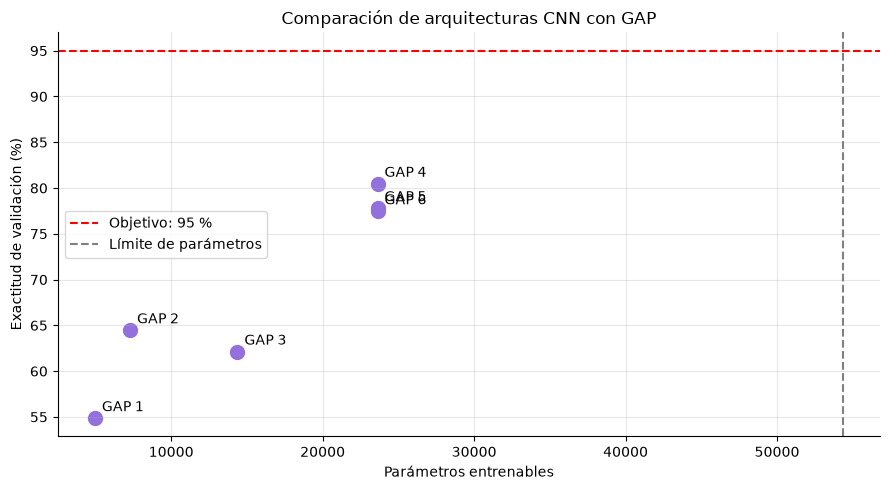

In [15]:
plt.figure(figsize=(9, 5))

plt.scatter(
    tabla_gap["Parámetros"],
    tabla_gap["Validación (%)"],
    s=100,
    color="mediumpurple"
)

for _, fila in tabla_gap.iterrows():
    plt.annotate(
        fila["Modelo"],
        (fila["Parámetros"], fila["Validación (%)"]),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.axhline(
    y=95,
    color="red",
    linestyle="--",
    label="Objetivo: 95 %"
)

plt.axvline(
    x=54330,
    color="gray",
    linestyle="--",
    label="Límite de parámetros"
)

plt.xlabel("Parámetros entrenables")
plt.ylabel("Exactitud de validación (%)")
plt.title("Comparación de arquitecturas CNN con GAP")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

#### 3.6. Análisis de los primeros experimentos

Ninguna de las seis arquitecturas logró superar el 95 % de exactitud en validación. Sin embargo, se observaron mejoras importantes respecto al GAP original.

La arquitectura GAP 4 obtuvo el mejor desempeño, alcanzando 80.47% con 23 626 parámetros entrenables. Las comparaciones muestran que aumentar la profundidad de la red permitió mejorar considerablemente la clasificación, mientras que incrementar únicamente el número de filtros no garantizó mejores resultados.

También se observó que MaxPooling obtuvo mejores resultados que AveragePooling y que eliminar el pooling intermedio.

Debido a que ninguna variante cumplió el objetivo, se realizarán experimentos adicionales modificando la distribución de las capas convolucionales y la ubicación del pooling.

In [16]:
def crear_cnn_gap_bloques(filtros=(16, 32, 32, 32),
                         pooling_despues=(2, 4)):

    capas = [keras.Input(shape=FORMA)]

    for i, n_filtros in enumerate(filtros, start=1):

        capas.append(
            keras.layers.Conv2D(
                filters=n_filtros,
                kernel_size=3,
                padding="same",
                activation="relu",
                name=f"conv_{i}"
            )
        )

        if i in pooling_despues:
            capas.append(
                keras.layers.MaxPooling2D(
                    pool_size=2,
                    name=f"pool_{i}"
                )
            )

    capas.append(keras.layers.GlobalAveragePooling2D())
    capas.append(keras.layers.Dense(10, activation="softmax"))

    return keras.Sequential(capas)

In [17]:
variantes_bloques = {
    "GAP 7": {
        "filtros": (16, 32, 32, 32),
        "pooling_despues": (2, 4)
    },
    "GAP 8": {
        "filtros": (16, 32, 32, 32),
        "pooling_despues": (1, 3)
    },
    "GAP 9": {
        "filtros": (16, 32, 32, 32),
        "pooling_despues": (2,)
    },
    "GAP 10": {
        "filtros": (16, 32, 32, 32),
        "pooling_despues": (1, 2, 3)
    }
}

for nombre, config in variantes_bloques.items():
    modelo = crear_cnn_gap_bloques(**config)

    print(
        f"{nombre}: {modelo.count_params():,} parámetros"
    )

GAP 7: 23,626 parámetros
GAP 8: 23,626 parámetros
GAP 9: 23,626 parámetros
GAP 10: 23,626 parámetros


#### 3.7. Evaluación de la ubicación del pooling

En los experimentos anteriores, GAP 4 obtuvo la mayor exactitud de validación (80.47 %). Sin embargo, ninguna arquitectura alcanzó el objetivo del 95 %.

Para investigar si la distribución espacial de las operaciones de pooling influye en el desempeño, se diseñaron cuatro variantes adicionales que conservan el mismo número de filtros y parámetros entrenables que GAP 4, pero modifican la ubicación de las capas MaxPooling.

In [18]:
resultados_bloques = []
modelos_bloques = {}
historiales_bloques = {}

for nombre, config in variantes_bloques.items():

    print(f"\nEntrenando {nombre}...")
    print(f"Pooling después de: {config['pooling_despues']}")

    # Reiniciar semilla antes de construir cada modelo
    keras.utils.set_random_seed(SEMILLA)

    # Crear arquitectura
    modelo = crear_cnn_gap_bloques(**config)

    # Entrenar durante 20 épocas
    historial = entrenar_modelo(modelo)

    # Guardar modelo e historial
    modelos_bloques[nombre] = modelo
    historiales_bloques[nombre] = historial.history

    # Registrar resultados
    resultados_bloques.append({
        "Modelo": nombre,
        "Filtros": str(config["filtros"]),
        "Pooling después de": str(config["pooling_despues"]),
        "Parámetros": sum(
            int(np.prod(p.shape))
            for p in modelo.trainable_weights
        ),
        "Validación (%)": historial.history["val_accuracy"][-1] * 100
    })

    print(
        f"Validación: "
        f"{historial.history['val_accuracy'][-1] * 100:.2f}%"
    )

tabla_bloques = pd.DataFrame(resultados_bloques)

display(tabla_bloques.round(2))


Entrenando GAP 7...
Pooling después de: (2, 4)
Validación: 92.27%

Entrenando GAP 8...
Pooling después de: (1, 3)
Validación: 93.27%

Entrenando GAP 9...
Pooling después de: (2,)
Validación: 89.40%

Entrenando GAP 10...
Pooling después de: (1, 2, 3)
Validación: 95.67%


,Modelo,Filtros,Pooling después de,Parámetros,Validación (%)
0,GAP 7,"(16, 32, 32, 32)","(2, 4)",23626,92.27
1,GAP 8,"(16, 32, 32, 32)","(1, 3)",23626,93.27
2,GAP 9,"(16, 32, 32, 32)","(2,)",23626,89.40
3,GAP 10,"(16, 32, 32, 32)","(1, 2, 3)",23626,95.67


In [19]:
# Recuperar resultados de GAP 4
referencia_gap4 = tabla_gap[
    tabla_gap["Modelo"] == "GAP 4"
][["Modelo", "Parámetros", "Validación (%)"]]

# Recuperar resultados de las nuevas variantes
nuevos_resultados = tabla_bloques[
    ["Modelo", "Parámetros", "Validación (%)"]
]

# Combinar resultados
comparacion_pooling = pd.concat(
    [referencia_gap4, nuevos_resultados],
    ignore_index=True
)

# Ordenar por exactitud
comparacion_pooling = comparacion_pooling.sort_values(
    "Validación (%)",
    ascending=False
)

display(comparacion_pooling.round(2))

,Modelo,Parámetros,Validación (%)
4,GAP 10,23626,95.67
2,GAP 8,23626,93.27
1,GAP 7,23626,92.27
3,GAP 9,23626,89.40
0,GAP 4,23626,80.47


La segunda exploración mostró una mejora considerable respecto a los experimentos iniciales. La arquitectura GAP 10 alcanzó una exactitud de validación del 95.67% utilizando 23 626 parámetros entrenables, cumpliendo ambos requisitos de la tarea.

Al comparar GAP 4 y GAP 10, que tienen los mismos filtros y parámetros, se observó una mejora de 15.20 puntos porcentuales. Esto sugiere que distribuir las operaciones de MaxPooling entre las capas convolucionales permite extraer características más útiles para la clasificación.

Estos resultados indican que la organización de las capas puede ser tan importante como la cantidad de parámetros del modelo.

Aunque GAP 10 ya cumple los requisitos, se realizarán experimentos adicionales para intentar reducir el número de parámetros sin disminuir la exactitud por debajo del 95%.

#### 3.8. Optimización del número de parámetros

Después de identificar que GAP 10 supera el 95% de exactitud en validación, se diseñaron cinco arquitecturas adicionales con el objetivo de reducir el número de parámetros entrenables.

In [20]:
variantes_compactas = {
    "GAP 11": {
        "filtros": (8, 16, 16, 16),
        "pooling_despues": (1, 2, 3)
    },
    "GAP 12": {
        "filtros": (8, 16, 24, 24),
        "pooling_despues": (1, 2, 3)
    },
    "GAP 13": {
        "filtros": (8, 24, 24, 24),
        "pooling_despues": (1, 2, 3)
    },
    "GAP 14": {
        "filtros": (12, 24, 24, 24),
        "pooling_despues": (1, 2, 3)
    },
    "GAP 15": {
        "filtros": (12, 32, 32, 32),
        "pooling_despues": (1, 2, 3)
    }
}

# Revisar parámetros
for nombre, config in variantes_compactas.items():
    modelo = crear_cnn_gap_bloques(**config)

    print(f"{nombre}: {modelo.count_params():,} parámetros")

GAP 11: 6,058 parámetros
GAP 12: 10,186 parámetros
GAP 13: 12,498 parámetros
GAP 14: 13,402 parámetros
GAP 15: 22,434 parámetros


In [21]:
resultados_compactos = []
modelos_compactos = {}
historiales_compactos = {}

for nombre, config in variantes_compactas.items():

    print(f"\nEntrenando {nombre}...")
    print(f"Filtros: {config['filtros']}")

    # Reiniciar semilla
    keras.utils.set_random_seed(SEMILLA)

    # Construir modelo
    modelo = crear_cnn_gap_bloques(**config)

    # Entrenar durante 20 épocas
    historial = entrenar_modelo(modelo)

    # Guardar modelo e historial
    modelos_compactos[nombre] = modelo
    historiales_compactos[nombre] = historial.history

    # Registrar resultados
    resultados_compactos.append({
        "Modelo": nombre,
        "Filtros": str(config["filtros"]),
        "Parámetros": sum(
            int(np.prod(p.shape))
            for p in modelo.trainable_weights
        ),
        "Validación (%)": historial.history["val_accuracy"][-1] * 100
    })

    print(
        f"Validación: "
        f"{historial.history['val_accuracy'][-1] * 100:.2f}%"
    )

# Tabla de resultados
tabla_compactos = pd.DataFrame(resultados_compactos)

display(tabla_compactos.round(2))



Entrenando GAP 11...
Filtros: (8, 16, 16, 16)
Validación: 93.73%

Entrenando GAP 12...
Filtros: (8, 16, 24, 24)
Validación: 94.47%

Entrenando GAP 13...
Filtros: (8, 24, 24, 24)
Validación: 96.07%

Entrenando GAP 14...
Filtros: (12, 24, 24, 24)
Validación: 95.73%

Entrenando GAP 15...
Filtros: (12, 32, 32, 32)
Validación: 96.53%


,Modelo,Filtros,Parámetros,Validación (%)
0,GAP 11,"(8, 16, 16, 16)",6058,93.73
1,GAP 12,"(8, 16, 24, 24)",10186,94.47
2,GAP 13,"(8, 24, 24, 24)",12498,96.07
3,GAP 14,"(12, 24, 24, 24)",13402,95.73
4,GAP 15,"(12, 32, 32, 32)",22434,96.53


In [22]:
# Recuperar GAP 10
referencia_gap10 = tabla_bloques[
    tabla_bloques["Modelo"] == "GAP 10"
][["Modelo", "Parámetros", "Validación (%)"]]

# Resultados de modelos compactos
nuevos_compactos = tabla_compactos[
    ["Modelo", "Parámetros", "Validación (%)"]
]

# Combinar tablas
comparacion_compactos = pd.concat(
    [referencia_gap10, nuevos_compactos],
    ignore_index=True
)

# Ordenar por número de parámetros
comparacion_compactos = comparacion_compactos.sort_values(
    "Parámetros"
)

# Identificar modelos que cumplen el objetivo
comparacion_compactos["Cumple objetivo"] = (
    (comparacion_compactos["Validación (%)"] > 95) &
    (comparacion_compactos["Parámetros"] < 54330)
)

display(comparacion_compactos.round(2))

,Modelo,Parámetros,Validación (%),Cumple objetivo
1,GAP 11,6058,93.73,False
2,GAP 12,10186,94.47,False
3,GAP 13,12498,96.07,True
4,GAP 14,13402,95.73,True
5,GAP 15,22434,96.53,True
0,GAP 10,23626,95.67,True


La reducción progresiva de filtros permitió identificar arquitecturas considerablemente más compactas que GAP 10, GAP 13, GAP 14 y GAP 15 superaron el 95 % de exactitud en validación. GAP 13 destacó por obtener una exactitud del 96.07 % utilizando únicamente 12 498 parámetros entrenables.

En comparación con la CNN original con Flatten, GAP 13 permite ahorrar 41 832 parámetros, lo que representa una reducción aproximada del 77 %.

Estos resultados muestran que es posible mantener una buena capacidad de clasificación utilizando una arquitectura considerablemente más pequeña. Además, la distribución de MaxPooling entre las capas convolucionales fue uno de los cambios más importantes para mejorar el desempeño del GAP original.

**¿Podemos reducir todavía más los parámetros?**

Se diseñarán cuatro variantes adicionales para investigar si es posible reducir todavía más el número de parámetros entrenables.

In [23]:
variantes_finales = {
    "GAP 16": {
        "filtros": (8, 20, 24, 24),
        "pooling_despues": (1, 2, 3)
    },
    "GAP 17": {
        "filtros": (8, 24, 20, 24),
        "pooling_despues": (1, 2, 3)
    },
    "GAP 18": {
        "filtros": (8, 24, 24, 20),
        "pooling_despues": (1, 2, 3)
    },
    "GAP 19": {
        "filtros": (8, 20, 20, 24),
        "pooling_despues": (1, 2, 3)
    }
}

for nombre, config in variantes_finales.items():
    modelo = crear_cnn_gap_bloques(**config)

    print(f"{nombre}: {modelo.count_params():,} parámetros")

GAP 16: 11,342 parámetros
GAP 17: 10,766 parámetros
GAP 18: 11,590 parámetros
GAP 19: 9,754 parámetros


In [24]:
resultados_finales = []
modelos_finales = {}
historiales_finales = {}

for nombre, config in variantes_finales.items():

    print(f"\nEntrenando {nombre}...")
    print(f"Filtros: {config['filtros']}")

    # Reiniciar semilla
    keras.utils.set_random_seed(SEMILLA)

    # Construir modelo
    modelo = crear_cnn_gap_bloques(**config)

    # Entrenar durante 20 épocas
    historial = entrenar_modelo(modelo)

    # Guardar modelo e historial
    modelos_finales[nombre] = modelo
    historiales_finales[nombre] = historial.history

    # Registrar resultados
    resultados_finales.append({
        "Modelo": nombre,
        "Filtros": str(config["filtros"]),
        "Parámetros": sum(
            int(np.prod(p.shape))
            for p in modelo.trainable_weights
        ),
        "Validación (%)": historial.history["val_accuracy"][-1] * 100
    })

    print(
        f"Validación: "
        f"{historial.history['val_accuracy'][-1] * 100:.2f}%"
    )

tabla_finales = pd.DataFrame(resultados_finales)

display(tabla_finales.round(2))



Entrenando GAP 16...
Filtros: (8, 20, 24, 24)
Validación: 95.33%

Entrenando GAP 17...
Filtros: (8, 24, 20, 24)
Validación: 94.87%

Entrenando GAP 18...
Filtros: (8, 24, 24, 20)
Validación: 95.20%

Entrenando GAP 19...
Filtros: (8, 20, 20, 24)
Validación: 95.40%


,Modelo,Filtros,Parámetros,Validación (%)
0,GAP 16,"(8, 20, 24, 24)",11342,95.33
1,GAP 17,"(8, 24, 20, 24)",10766,94.87
2,GAP 18,"(8, 24, 24, 20)",11590,95.20
3,GAP 19,"(8, 20, 20, 24)",9754,95.40


In [25]:
# Recuperar GAP 13
referencia_gap13 = tabla_compactos[
    tabla_compactos["Modelo"] == "GAP 13"
][["Modelo", "Parámetros", "Validación (%)"]]

# Recuperar las variantes nuevas
nuevas_variantes = tabla_finales[
    ["Modelo", "Parámetros", "Validación (%)"]
]

# Combinar resultados
comparacion_final = pd.concat(
    [referencia_gap13, nuevas_variantes],
    ignore_index=True
)

# Identificar cuáles cumplen los requisitos
comparacion_final["Cumple objetivo"] = (
    (comparacion_final["Validación (%)"] > 95) &
    (comparacion_final["Parámetros"] < 54330)
)

# Ordenar por parámetros
comparacion_final = comparacion_final.sort_values(
    "Parámetros"
)

display(comparacion_final.round(2))


,Modelo,Parámetros,Validación (%),Cumple objetivo
4,GAP 19,9754,95.40,True
2,GAP 17,10766,94.87,False
1,GAP 16,11342,95.33,True
3,GAP 18,11590,95.20,True
0,GAP 13,12498,96.07,True


#### 3.9. Selección de la arquitectura final

Después de evaluar 19 variantes con Global Average Pooling, se seleccionó GAP 19, ya que fue la arquitectura con menor número de parámetros entre las que superaron el 95% de exactitud en validación.

GAP 19 utiliza cuatro capas convolucionales con 8, 20, 20 y 24 filtros, respectivamente, y tres operaciones de MaxPooling distribuidas entre las convoluciones.

El modelo obtuvo una exactitud de validación del 95.40% con 9 754 parámetros entrenables. En comparación con la CNN original con Flatten, que utiliza 54 330 parámetros, representa un ahorro de 44 576 parámetros, equivalente al 82.05 %.

El cambio más importante para mejorar el desempeño fue distribuir las operaciones de MaxPooling entre las capas convolucionales. Posteriormente, reducir el número de filtros permitió obtener una arquitectura más compacta sin disminuir la exactitud por debajo del objetivo establecido.

In [28]:
# Recuperar el modelo seleccionado
modelo_gap_seleccionado = modelos_finales["GAP 19"]

# Verificar arquitectura y parámetros
modelo_gap_seleccionado.summary()

print(
    "\nParámetros entrenables:",
    sum(
        int(np.prod(p.shape))
        for p in modelo_gap_seleccionado.trainable_weights
    )
)

# Guardar el modelo entrenado
modelo_gap_seleccionado.save("cnn_gap_seleccionado.keras")

print("\nModelo guardado correctamente.")

Model: "sequential_37"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv_1 (Conv2D)                 │ (None, 36, 36, 8)      │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_1 (MaxPooling2D)           │ (None, 18, 18, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_2 (Conv2D)                 │ (None, 18, 18, 20)     │         1,460 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_2 (MaxPooling2D)           │ (None, 9, 9, 20)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_3 (Conv2D)                 │ (None, 9, 9, 20)       │         3,620 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_3 (MaxPooling2D)           │ (None, 4, 4, 20)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_4 (Conv2D)                 │ (None, 4, 4, 24)       │         4,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_37     │ (None, 24)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_37 (Dense)                │ (None, 10)             │           250 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,264 (114.32 KB)

 Trainable params: 9,754 (38.10 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 19,510 (76.21 KB)


Parámetros entrenables: 9754

Modelo guardado correctamente.


### 4. Evaluación de robustez ante desplazamientos

Se evaluarán los modelos Flatten, GAP base y GAP 19 sobre las mismas imágenes de prueba, aplicando desplazamientos de 0, 2 y 4 píxeles. Para cada distancia distinta de cero, se promediará la exactitud obtenida en las cuatro direcciones.

Se comparará tanto la caída de exactitud como el rendimiento que conserva cada modelo al desplazar los dígitos.

,Modelo,0 px (%),2 px (%),4 px (%),Caída a 4 px (pp)
0,CNN + Flatten,96.70,83.00,37.11,59.59
1,CNN + GAP base,43.55,43.56,43.51,0.04
2,GAP 19,95.45,88.38,71.92,23.53


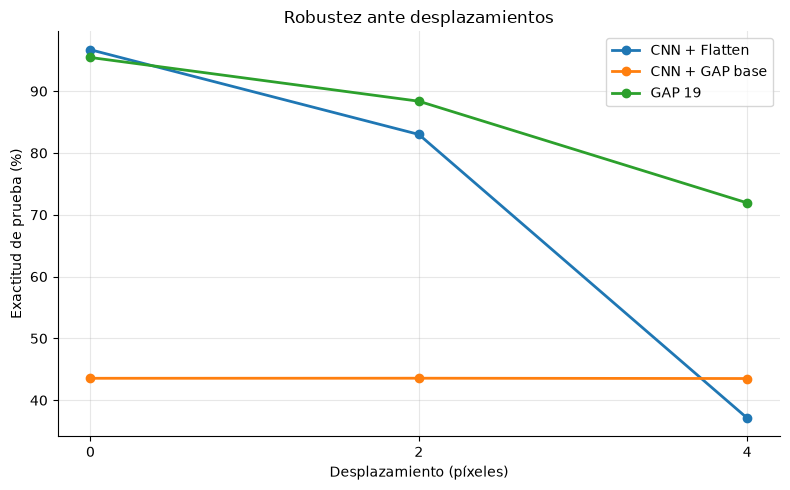

In [30]:
def desplazar(imagenes, dy, dx):
    if max(abs(dy), abs(dx)) > MARGEN:
        raise ValueError("Desplazamiento fuera del margen.")

    alto, ancho = imagenes.shape[1:3]
    resultado = np.zeros_like(imagenes)

    origen_y = slice(max(-dy, 0), alto - max(dy, 0))
    origen_x = slice(max(-dx, 0), ancho - max(dx, 0))
    destino_y = slice(max(dy, 0), alto - max(-dy, 0))
    destino_x = slice(max(dx, 0), ancho - max(-dx, 0))

    resultado[:, destino_y, destino_x, :] = (
        imagenes[:, origen_y, origen_x, :]
    )
    return resultado


modelos_comparacion = {
    "CNN + Flatten": modelo_flatten,
    "CNN + GAP base": modelo_gap_base,
    "GAP 19": modelo_gap_seleccionado
}

distancias = [0, 2, 4]
resultados = []

for nombre, modelo in modelos_comparacion.items():
    fila = {"Modelo": nombre}

    for d in distancias:
        direcciones = [(0, 0)] if d == 0 else [
            (d, 0), (-d, 0), (0, d), (0, -d)
        ]

        exactitudes = []

        for dy, dx in direcciones:
            imagenes = desplazar(X_prueba, dy, dx)
            pred = modelo.predict(
                imagenes, batch_size=LOTE, verbose=0
            ).argmax(axis=1)

            exactitudes.append(100 * np.mean(pred == y_prueba))

        fila[f"{d} px (%)"] = np.mean(exactitudes)

    fila["Caída a 4 px (pp)"] = (
        fila["0 px (%)"] - fila["4 px (%)"]
    )
    resultados.append(fila)

tabla_desplazamiento = pd.DataFrame(resultados)
display(tabla_desplazamiento.round(2))

# Gráfica
plt.figure(figsize=(8, 5))

for _, fila in tabla_desplazamiento.iterrows():
    plt.plot(
        distancias,
        [fila[f"{d} px (%)"] for d in distancias],
        marker="o",
        linewidth=2,
        label=fila["Modelo"]
    )

plt.xlabel("Desplazamiento (píxeles)")
plt.ylabel("Exactitud de prueba (%)")
plt.title("Robustez ante desplazamientos")
plt.xticks(distancias)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

Los resultados muestran que GAP 19 presenta una mayor robustez frente a los desplazamientos que la CNN con Flatten. Aunque Flatten obtuvo una exactitud ligeramente superior sin desplazamiento (96.70% frente a 95.45%), su desempeño disminuyó considerablemente al mover los dígitos.

La diferencia comienza a observarse desde los 2 píxeles, donde GAP 19 alcanzó una exactitud del 88.38 %, frente al 83.00 % de Flatten. A los 4 píxeles, esta diferencia fue todavía más evidente: GAP 19 conservó una exactitud del 71.92 %, mientras que Flatten cayó hasta el 37.11 %. Esto representa una pérdida de 23.53 y 59.59 puntos porcentuales, respectivamente.

Por otro lado, el GAP base prácticamente no presentó cambios en su exactitud, pero se mantuvo alrededor del 43.5 %, lo que demuestra que una menor sensibilidad al desplazamiento no necesariamente implica un mejor desempeño.

En general, los resultados sugieren que **GAP favorece la robustez frente a cambios de posición**, pero necesita una arquitectura adecuada para aprender características suficientemente discriminativas. GAP 19 logró combinar ambas ventajas, manteniendo una exactitud alta en las imágenes originales y conservando un mejor desempeño que Flatten al desplazar los dígitos.

### 5. Conclusiones

El cambio más importante para que la CNN con GAP superara el 95% de exactitud en validación fue modificar la ubicación de las capas MaxPooling. Al distribuirlas entre las convoluciones, en lugar de colocar una sola al final, la exactitud aumentó considerablemente sin necesidad de incrementar los parámetros entrenables.

Después de explorar distintas configuraciones, se seleccionó **GAP 19**, con cuatro capas convolucionales de 8, 20, 20 y 24 filtros. Este modelo alcanzó una exactitud de validación del **95.40 %**, utilizando únicamente **9 754 parámetros**, lo que representa un ahorro de 44 576 parámetros (82.05 %) respecto a la CNN con Flatten.

Finalmente, GAP 19 demostró una mayor robustez frente a los desplazamientos. Aunque Flatten obtuvo una exactitud ligeramente superior en las imágenes originales, GAP 19 comenzó a superarlo desde los **2 píxeles de desplazamiento**, y la diferencia aumentó considerablemente a los 4 píxeles.

En general, los experimentos muestran que no solo importa la cantidad de parámetros de una CNN, sino también cómo se organizan sus capas. Una arquitectura compacta y bien diseñada puede conseguir una buena exactitud y ser más robusta frente a cambios en la posición de las imágenes.

### Referencias
¿Qué son las redes neuronales convolucionales? | IBM. (2026, 26 agosto). https://www.ibm.com/mx-es/think/topics/convolutional-neural-networks

### Declaración de uso de IA
Para el desarrollo de esta práctica se utilizó ChatGPT (OpenAI) como herramienta de apoyo. Los resultados, el código y las interpretaciones obtenidas fueron revisados y ajustados antes de su incorporación a la tarea. 